<a href="https://colab.research.google.com/github/Pamodya-Wijesinghe/EN3160-Assignment-2-on-Fitting-and-Alignment/blob/main/EN3160_Assignment_02_230727P.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


Reduced image dimensions: (360, 360)
Sigma range: 0.9 to 15.0
LoG scale-space candidates surviving flower validation: 258
Accepted circles after duplicate suppression: 207
Largest-circle parameters:
  x   y  sigma  log_blob_radius  display_radius
281 336   8.24            11.66           21.57
105 255   6.49             9.18           16.98
178 260   6.11             8.64           15.99
179 329   6.11             8.64           15.99
273 257   5.11             7.22           13.36
161 290   4.53             6.41           11.85
189 240   4.53             6.41           11.85
 63 243   4.53             6.41           11.85
 70 286   4.27             6.03           11.16
 19 249   4.27             6.03           11.16
Results saved to: /content/drive/MyDrive/EN3160_Assignment_02/results


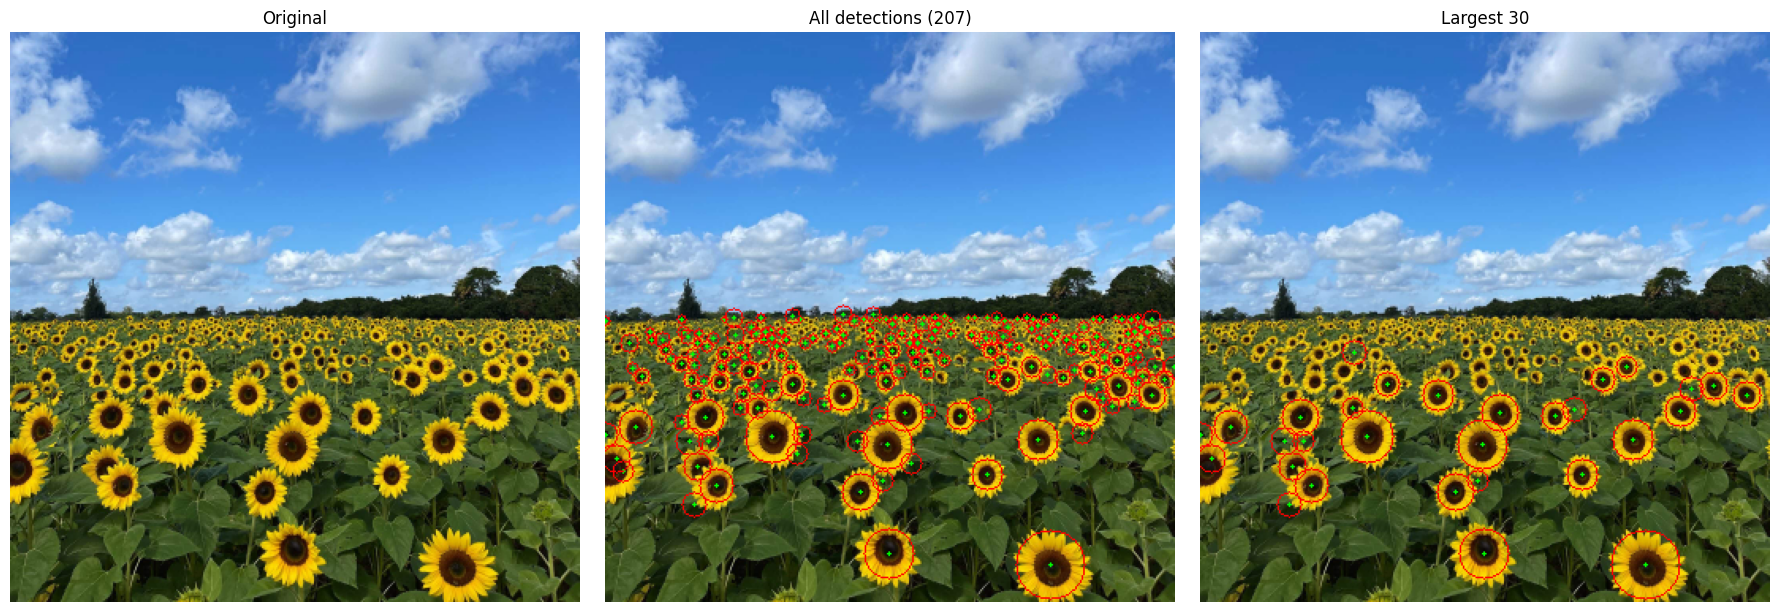

In [ ]:
from pathlib import Path
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, gaussian_laplace, maximum_filter

project_dir = Path('/content/drive/MyDrive/EN3160_Assignment_02')
image_path = project_dir / 'images/the_berry_farms_sunflower_field.jpeg'
results_dir = project_dir / 'results'
results_dir.mkdir(parents=True, exist_ok=True)

# Read at quarter size, exactly as required by the assignment.
im = cv.imread(str(image_path), cv.IMREAD_REDUCED_COLOR_4)
if im is None:
    raise FileNotFoundError(f'Could not read {image_path}')
H, W = im.shape[:2]
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
hsv = cv.cvtColor(im, cv.COLOR_BGR2HSV)

# The yellow mask is only an aid to select flowers. Circle candidates
# are still generated through scale-normalized LoG + scale-space extrema.
yellow = ((hsv[:, :, 0] > 13) & (hsv[:, :, 0] < 40) &
          (hsv[:, :, 1] > 90) & (hsv[:, :, 2] > 75)).astype(np.float32)
nearby_yellow = np.maximum(gaussian_filter(yellow, 3),
                           gaussian_filter(yellow, 7))

# High response where the pixel is dark but yellow petals are nearby.
flower_response = np.maximum(0.0, 0.78-gray) * nearby_yellow

# Scale-normalized Laplacian of Gaussian at different sigma values.
sigmas = np.geomspace(0.9, 15.0, 48)
log_stack = np.stack([
    sigma**2 * gaussian_laplace(flower_response, sigma=float(sigma))
    for sigma in sigmas
], axis=2)

# Negative signed LoG identifies positive (bright) blob maxima in the
# derived flower-response map; square it after selecting this polarity.
response = np.maximum(-log_stack, 0)**2
local_max = maximum_filter(response, size=(5, 5, 3), mode='constant')
peak_mask = (response == local_max) & (response > .025 * response.max())
ys, xs, levels = np.where(peak_mask)

candidates = []
for y, x, k in zip(ys, xs, levels):
    sigma = float(sigmas[k])
    r_blob = float(np.sqrt(2)*sigma)

    # The sunflowers begin near row 176 in this 360px-high image.
    # The minimum expected flower-center size increases towards camera.
    if y < int(176 * H / 360):
        continue
    if r_blob < 1.2 + 0.026 * max(y - (180 * H / 360), 0):
        continue

    # Examine only a local window, not the entire image for each peak.
    reach = int(np.ceil(2.8*r_blob))
    x0, x1 = max(0, x-reach), min(W, x+reach+1)
    y0, y1 = max(0, y-reach), min(H, y+reach+1)
    YY, XX = np.ogrid[y0:y1, x0:x1]
    dist2 = (XX-x)**2+(YY-y)**2
    ring = (dist2 >= (1.3*r_blob)**2) & (dist2 <= (2.5*r_blob)**2)
    core = dist2 <= (0.6*r_blob)**2
    if ring.sum() < 10 or core.sum() == 0:
        continue

    ring_yellow = float(yellow[y0:y1, x0:x1][ring].mean())
    center_yellow = float(yellow[y0:y1, x0:x1][core].mean())
    center_gray = float(gray[y0:y1, x0:x1][core].mean())
    ring_gray = float(gray[y0:y1, x0:x1][ring].mean())

    # Reject candidates that do not have a dark center and yellow petals.
    if (ring_yellow < .26 or ring_gray-center_gray < .10 or
            ring_yellow-center_yellow < .07):
        continue

    candidates.append({
        'x': int(x), 'y': int(y), 'sigma': sigma,
        'log_blob_radius': r_blob,
        'display_radius': 1.85*r_blob,
        'score': float(response[y, x, k]),
        'yellow_fraction': ring_yellow,
    })

# Nonmaximum selection to reduce repeated circles at the same flower.
candidates.sort(key=lambda c: c['score'] * c['yellow_fraction'], reverse=True)
detections = []
for item in candidates:
    if any(np.hypot(item['x']-d['x'], item['y']-d['y']) <
           1.5*max(item['log_blob_radius'], d['log_blob_radius'])
           for d in detections):
        continue
    detections.append(item)

# Draw all accepted circles and also the 30 largest ones.
def draw_circles(items):
    out = im.copy()
    for item in items:
        center = (item['x'], item['y'])
        cv.circle(out, center, max(1, round(item['display_radius'])), (0, 0, 255), 1)
        cv.circle(out, center, 1, (0, 255, 0), -1)
    return out

largest_30 = sorted(detections, key=lambda d: d['display_radius'], reverse=True)[:30]
all_view = draw_circles(detections)
large_view = draw_circles(largest_30)
cv.imwrite(str(results_dir / 'q1_all_detected.png'), all_view)
cv.imwrite(str(results_dir / 'q1_largest_30.png'), large_view)

cols = ['x', 'y', 'sigma', 'log_blob_radius', 'display_radius', 'score', 'yellow_fraction']
parameters = pd.DataFrame(largest_30, columns=cols)
parameters.to_csv(results_dir / 'q1_largest_30_parameters.csv', index=False)

print('Reduced image dimensions:', (H, W))
print('Sigma range:', round(sigmas[0],2), 'to', round(sigmas[-1],2))
print('LoG scale-space candidates surviving flower validation:', len(candidates))
print('Accepted circles after duplicate suppression:', len(detections))
print('Largest-circle parameters:')
print(parameters[['x','y','sigma','log_blob_radius','display_radius']].head(10).round(2).to_string(index=False))
print('Results saved to:', results_dir)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, img, title in zip(ax, [im, all_view, large_view],
                         ['Original', f'All detections ({len(detections)})', 'Largest 30']):
    a.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    a.set_title(title)
    a.axis('off')
plt.tight_layout()
plt.show()


In [16]:

from google.colab import drive
from pathlib import Path

# Mount Google Drive if not already mounted
drive.mount('/content/drive')

# Correct project path without the leading space
project_dir = Path("/content/drive/MyDrive/EN3160_Assignment_02")
results_dir = project_dir / "results"

# Create results folder if needed
results_dir.mkdir(parents=True, exist_ok=True)

print("Project folder exists:", project_dir.exists())
print("Results folder:", results_dir)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder exists: True
Results folder: /content/drive/MyDrive/EN3160_Assignment_02/results


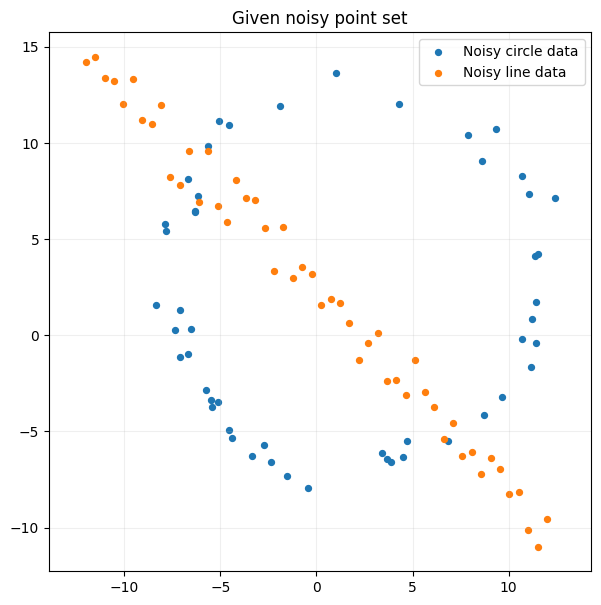

Shape of X: (100, 2)


In [17]:
# --- Assignment Listing 1, with a fixed seed for repeatable results ---
np.random.seed(0)
N=100
half_n = N//2
r_gt=10.0
center_gt=np.array([2.0,3.0]); circle_noise=r_gt/16
angle=np.random.uniform(0,2*np.pi,half_n)
noise=circle_noise*np.random.randn(half_n)
X_circ=np.column_stack((center_gt[0]+(r_gt+noise)*np.cos(angle), center_gt[1]+(r_gt+noise)*np.sin(angle)))
slope_gt=-1.0; intercept_gt=2.0
x=np.linspace(-12,12,half_n)
y=slope_gt*x+intercept_gt+1.0*np.random.randn(half_n)
X_line=np.column_stack((x,y))
X=np.vstack([X_circ,X_line])

plt.figure(figsize=(7,7))
plt.scatter(X_circ[:,0],X_circ[:,1],s=18,label='Noisy circle data')
plt.scatter(X_line[:,0],X_line[:,1],s=18,label='Noisy line data')
plt.axis('equal'); plt.grid(alpha=0.2); plt.legend(); plt.title('Given noisy point set'); plt.show()
print('Shape of X:',X.shape)

In [18]:
def sample_line(points):
    vector = points[1]-points[0]
    length=np.linalg.norm(vector)
    if length < 1e-10: return None
    normal=np.array([-vector[1],vector[0]])/length
    distance = float(normal@points[0])
    if distance<0: normal, distance = -normal, -distance
    return (*normal, distance)

def line_residual(points, model):
    a,b,d=model
    return np.abs(a*points[:,0]+b*points[:,1]-d)

def fit_line_tls(points):
    mean=points.mean(axis=0)
    U=points-mean
    evals,evecs=np.linalg.eigh(U.T@U)
    normal=evecs[:,np.argmin(evals)]
    normal=normal/np.linalg.norm(normal)
    distance=float(normal@mean)
    if distance<0: normal, distance=-normal,-distance
    return (*normal, distance)

def ransac_line(points, threshold=1.5, min_inliers=30, iterations=500, rng=None):
    if rng is None: rng=np.random.default_rng(0)
    best=None
    for _ in range(iterations):
        sample_ids=rng.choice(len(points),2,replace=False)
        model=sample_line(points[sample_ids])
        if model is None: continue
        residuals=line_residual(points,model)
        inlier_mask=residuals<threshold
        count=np.count_nonzero(inlier_mask)
        if count<min_inliers: continue
        mse=float(np.mean(residuals[inlier_mask]**2))
        if best is None or count>best['count'] or (count==best['count'] and mse<best['mse']):
            best={'sample_ids':sample_ids.copy(),'sample_model':model,'raw_mask':inlier_mask,'count':count,'mse':mse}
    if best is None:raise RuntimeError('No line found')
    refined=fit_line_tls(points[best['raw_mask']])
    final_mask=line_residual(points,refined)<threshold
    refined=fit_line_tls(points[final_mask])
    final_mask=line_residual(points,refined)<threshold
    return {'sample_ids':best['sample_ids'],'sample_model':best['sample_model'],'model':refined,'mask':final_mask,'raw_count':best['count']}

In [19]:
def sample_circle(points):
    p1,p2,p3=points
    A=2*np.array([p2-p1,p3-p1],dtype=float)
    B=np.array([p2@p2-p1@p1, p3@p3-p1@p1],dtype=float)
    if abs(np.linalg.det(A))<1e-5 or np.linalg.cond(A)>1e4:
        return None
    c=np.linalg.solve(A,B)
    r=float(np.linalg.norm(p1-c))
    if not (1.0<r<30.0):return None
    return (float(c[0]),float(c[1]),r)

def circle_residual(points,params):
    cx,cy,r=params
    return np.abs(np.linalg.norm(points-[cx,cy],axis=1)-r)

def fit_circle_optimized(points,init):
    def objective(v):
        distances=np.linalg.norm(points-v[:2],axis=1)
        return np.mean((distances-v[2])**2)
    result=minimize(objective, x0=np.asarray(init),method='L-BFGS-B',bounds=[(None,None),(None,None),(1e-5,None)])
    if not result.success:
        print('Optimizer:',result.message)
    return tuple(result.x)

def ransac_circle(points, threshold=1.25, min_inliers=26, iterations=1500, rng=None):
    if rng is None:rng=np.random.default_rng(1)
    best=None
    for _ in range(iterations):
        sample_ids=rng.choice(len(points),3,replace=False)
        model=sample_circle(points[sample_ids])
        if model is None:continue
        residuals=circle_residual(points,model)
        inlier_mask=residuals<threshold
        count=int(np.count_nonzero(inlier_mask))
        if count<min_inliers:continue
        mse=float(np.mean(residuals[inlier_mask]**2))
        if best is None or count>best['count'] or (count==best['count'] and mse<best['mse']):
            best={'sample_ids':sample_ids.copy(),'sample_model':model,'raw_mask':inlier_mask,'count':count,'mse':mse}
    if best is None:raise RuntimeError('No circle found: adjust threshold and min_inliers')
    refined=fit_circle_optimized(points[best['raw_mask']],best['sample_model'])
    final_mask=circle_residual(points,refined)<threshold
    refined=fit_circle_optimized(points[final_mask],refined)
    final_mask=circle_residual(points,refined)<threshold
    return {'sample_ids':best['sample_ids'],'sample_model':best['sample_model'],'model':refined,'mask':final_mask,'raw_count':best['count']}

In [21]:

from scipy.optimize import minimize


In [22]:
# Carefully chosen initial RANSAC settings
LINE_THRESHOLD = 1.5      # orthogonal distance in coordinate units
LINE_MIN_INLIERS = 30
CIRCLE_THRESHOLD = 1.25   # radial distance error
CIRCLE_MIN_INLIERS = 26

rng = np.random.default_rng(230727)
line = ransac_line(X, threshold=LINE_THRESHOLD,
                   min_inliers=LINE_MIN_INLIERS,
                   iterations=500, rng=rng)

# Subtract line consensus before fitting circle
remaining = X[~line['mask']]
circle = ransac_circle(remaining, threshold=CIRCLE_THRESHOLD,
                       min_inliers=CIRCLE_MIN_INLIERS,
                       iterations=1500, rng=rng)

a,b,d = line['model']
cx,cy,r = circle['model']
print(f'Line a={a:.4f}, b={b:.4f}, d={d:.4f}')
print(f'Unit normal norm = {np.hypot(a,b):.8f}')
print(f'Line inliers = {line["mask"].sum()} / {len(X)}')
print(f'Circle center = ({cx:.4f}, {cy:.4f}), radius = {r:.4f}')
print(f'Circle inliers = {circle["mask"].sum()} / {len(remaining)} remaining points')


Line a=0.7210, b=0.6930, d=1.5724
Unit normal norm = 1.00000000
Line inliers = 54 / 100
Circle center = (1.8982, 3.0101), radius = 9.8314
Circle inliers = 44 / 46 remaining points


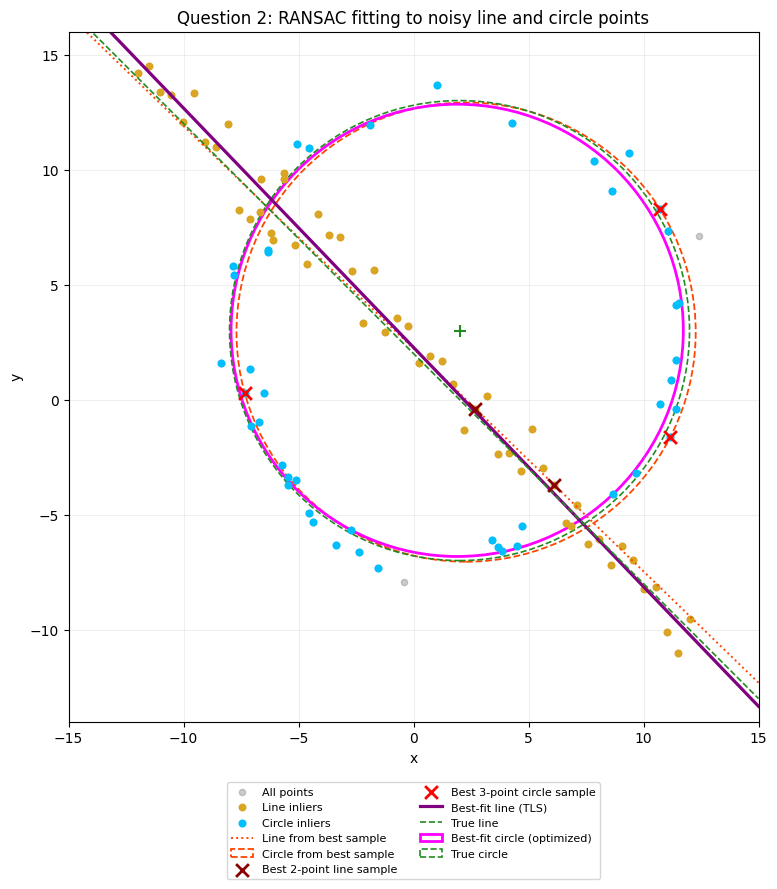

Saved to: /content/drive/MyDrive/EN3160_Assignment_02/results/q2_ransac_line_circle.png


In [23]:
def plot_line(ax,model,x_limits,**kwargs):
    a,b,d=model
    if abs(b)>1e-10:
        xx=np.array(x_limits)
        yy=(d-a*xx)/b
        ax.plot(xx, yy,**kwargs)
    else:
        ax.axvline(d/a,**kwargs)

fig,ax=plt.subplots(figsize=(9,9))
ax.scatter(X[:,0],X[:,1],c='gray',alpha=0.4,s=20,label='All points',zorder=1)
ax.scatter(X[line['mask'],0],X[line['mask'],1],s=22,c='goldenrod',label='Line inliers',zorder=2)
ax.scatter(remaining[circle['mask'],0],remaining[circle['mask'],1],s=23,c='deepskyblue',label='Circle inliers',zorder=3)
plot_line(ax, sample_line(X[line['sample_ids']]), [-15,15], c='orangered', ls=':',lw=1.4, label='Line from best sample')
ax.add_patch(plt.Circle(circle['sample_model'][:2], circle['sample_model'][2],fill=False,ec='orangered',ls='--',lw=1.3,label='Circle from best sample'))
ax.scatter(X[line['sample_ids'],0],X[line['sample_ids'],1], marker='x',s=85,c='darkred',lw=2,label='Best 2-point line sample', zorder=5)
ax.scatter(remaining[circle['sample_ids'],0],remaining[circle['sample_ids'],1],marker='x',s=85,c='red',lw=2,label='Best 3-point circle sample',zorder=5)
plot_line(ax,line['model'],[-15,15],c='purple',lw=2.3,label='Best-fit line (TLS)')
plot_line(ax,(1/np.sqrt(2),1/np.sqrt(2),2/np.sqrt(2)),[-15,15],c='forestgreen',ls='--',lw=1.2,label='True line')
ax.add_patch(plt.Circle(circle['model'][:2],circle['model'][2],fill=False,ec='magenta',lw=2,label='Best-fit circle (optimized)'))
ax.add_patch(plt.Circle(center_gt,r_gt,fill=False,ec='forestgreen',ls='--',lw=1.2,label='True circle'))
ax.scatter(*center_gt,marker='+',c='forestgreen',s=65)
ax.set_xlim(-15,15);ax.set_ylim(-14,16);ax.set_aspect('equal',adjustable='box');ax.grid(alpha=0.2);ax.set_xlabel('x');ax.set_ylabel('y');ax.set_title('Question 2: RANSAC fitting to noisy line and circle points')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), fontsize=8, ncol=2)
fig.tight_layout();fig.savefig(results_dir / 'q2_ransac_line_circle.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved to:', results_dir / 'q2_ransac_line_circle.png')

In [24]:
circle_first = ransac_circle(X, threshold=CIRCLE_THRESHOLD,
                             min_inliers=CIRCLE_MIN_INLIERS,
                             iterations=1500,
                             rng=np.random.default_rng(52))
remaining_after_circle = X[~circle_first['mask']]
line_second = ransac_line(remaining_after_circle,
                         threshold=LINE_THRESHOLD,
                         min_inliers=LINE_MIN_INLIERS,
                         iterations=500,
                         rng=np.random.default_rng(53))
print('LINE FIRST:')
print('  line inliers:',line['mask'].sum(), 'circle inliers:',circle['mask'].sum())
print('  fitted line (a,b,d):', np.round(line['model'],3))
print('  fitted circle (cx,cy,r):', np.round(circle['model'],3))
print('CIRCLE FIRST:')
print('  circle inliers:',circle_first['mask'].sum(),'line inliers:',line_second['mask'].sum())
print('  fitted circle (cx,cy,r):',np.round(circle_first['model'],3))
print('  fitted line (a,b,d):',np.round(line_second['model'],3))

LINE FIRST:
  line inliers: 54 circle inliers: 44
  fitted line (a,b,d): [0.721 0.693 1.572]
  fitted circle (cx,cy,r): [1.898 3.01  9.831]
CIRCLE FIRST:
  circle inliers: 57 line inliers: 41
  fitted circle (cx,cy,r): [1.902 3.018 9.88 ]
  fitted line (a,b,d): [0.723 0.691 1.664]
